# Разведывательный анализ данных

### Назначение: 
Разведывательный анализ данных (EDA).
### Содержимое:
- Визуализации ЭЭГ-сигналов (покой, таблицы Шульте).
- Первичная статистика: длительность записей, частота дискретизации, пропуски, артефакты.
- Анализ распределений по группам (норма, ПТСР, соматоформные).
- Выявление аномалий и выбросов.
- Первичные гипотезы о признаках, связанных с ПТСР.
- Анализ доступных конфаундеров: возраст (где известен), пол, поведенческие показатели.

**Важная особенность аппаратуры, которую нужно держать в голове на каждом
шаге ниже: референсный электрод расположен на левом ухе.** Это значит, что
левополушарные каналы (Fp1, T3, O1) физически ближе к референсу, чем
правополушарные (Fp2, T4, O2) — асимметрия амплитуды между полушариями
может быть частично или полностью артефактом схемы отведения, а не
реальной физиологией. Ниже это проверяется отдельно (раздел 6), **до**
того, как делать какие-либо выводы про фронтальную/височную асимметрию.

### Импорты и конфигурация

In [1]:
import re
import random
import warnings
from pathlib import Path
from collections import defaultdict
 
import numpy as np
import pandas as pd
from scipy import signal, stats as sps
 
import mne
 
import matplotlib.pyplot as plt
import seaborn as sns
 
warnings.filterwarnings("ignore")
mne.set_log_level("ERROR")
sns.set_theme(style="whitegrid")
 
%matplotlib inline

In [2]:
DATA_DIR = Path("/home/karpushenkova/atacheskaya-panika/data/neurodiagnostics-train")  # подставьте свой путь
 
CHANNELS = ["Fp1", "Fp2", "T3", "T4", "O1", "O2"]
LEFT_CH = ["Fp1", "T3", "O1"]
RIGHT_CH = ["Fp2", "T4", "O2"]
 
GROUPS = ["Норма", "ПТСР", "Соматоформные"]  # поправьте под реальные имена папок, если отличаются
 
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

In [4]:
def classify_file(stem: str) -> str:
    """Тип файла по имени: 'rest' (покой) или 'task_<n>' (n-я таблица Шульте)."""
    if re.search(r"(?:^|[_\\-\\s])(п|p|rest|покой)$", stem, re.I):
        return "rest"
    m = re.search(r"(?:^|[_\\-\\s])(\\d+)$", stem)
    return f"task_{m.group(1)}" if m else "unknown"
 
 
def get_age(group_name: str, subj_name: str):
    """Возраст закодирован в имени папки только для группы 'Норма' (п. 3.1 ТЗ)."""
    if not group_name.lower().startswith("норм"):
        return None
    m = re.search(r"_(\\d+)$", subj_name)
    return int(m.group(1)) if m else None

### Инвентаризация данных

Сколько испытуемых в каждой группе, у всех ли по 6 файлов (покой + 5 таблиц),
нет ли пустых/битых папок.

In [5]:
inventory_rows = []
for group_dir in sorted(DATA_DIR.iterdir()):
    if not group_dir.is_dir():
        continue
    for subj_dir in sorted(group_dir.iterdir()):
        if not subj_dir.is_dir():
            continue
        files = sorted(subj_dir.glob("*.edf"))
        kinds = [classify_file(f.stem) for f in files]
        inventory_rows.append(dict(
            group=group_dir.name,
            subject=subj_dir.name,
            age=get_age(group_dir.name, subj_dir.name),
            n_files=len(files),
            has_rest=("rest" in kinds),
            n_tasks=sum(k.startswith("task") for k in kinds),
            unknown_files=[f.name for f, k in zip(files, kinds) if k == "unknown"],
        ))
 
inv_df = pd.DataFrame(inventory_rows)
print("Всего испытуемых:", len(inv_df))
print(inv_df.groupby("group").size())

Всего испытуемых: 166
group
Норма            67
ПТСР             25
Соматоформные    74
dtype: int64


In [6]:
print("Распределение количества файлов на испытуемого (ожидается 6):")
print(inv_df["n_files"].value_counts().sort_index())
 
print("\\nИспытуемые без записи покоя:")
print(inv_df.loc[~inv_df["has_rest"], ["group", "subject", "n_files"]])
 
print("\\nИспытуемые с нестандартным числом таблиц (ожидается 5):")
print(inv_df.loc[inv_df["n_tasks"] != 5, ["group", "subject", "n_tasks"]])
 
unknown_all = inv_df.loc[inv_df["unknown_files"].map(len) > 0, ["group", "subject", "unknown_files"]]
print("\\nФайлы, не распознанные classify_file (нужно поправить regex или это мусорные файлы):")
print(unknown_all)

Распределение количества файлов на испытуемого (ожидается 6):
n_files
6    166
Name: count, dtype: int64
\nИспытуемые без записи покоя:
             group   subject  n_files
0            Норма  КС010_19        6
1            Норма  КС011_25        6
2            Норма  КС012_58        6
3            Норма  КС013_23        6
4            Норма  КС014_22        6
..             ...       ...      ...
161  Соматоформные     ZAQH1        6
162  Соматоформные     ZILO6        6
163  Соматоформные     ZJLO6        6
164  Соматоформные     ZWAX5        6
165  Соматоформные     ZXCV1        6

[166 rows x 3 columns]
\nИспытуемые с нестандартным числом таблиц (ожидается 5):
             group   subject  n_tasks
0            Норма  КС010_19        0
1            Норма  КС011_25        0
2            Норма  КС012_58        0
3            Норма  КС013_23        0
4            Норма  КС014_22        0
..             ...       ...      ...
161  Соматоформные     ZAQH1        0
162  Соматоформные    

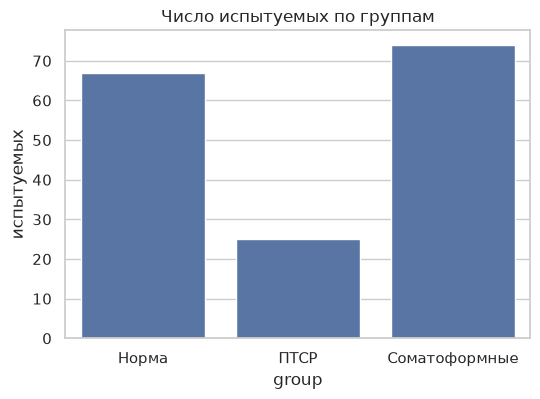

In [9]:
plt.figure(figsize=(6, 4))
sns.countplot(data=inv_df, x="group", order=GROUPS)
plt.title("Число испытуемых по группам")
plt.ylabel("испытуемых")
plt.show()

### Первичная статистика записей

Длительность, частота дискретизации, единицы измерения — то, что ТЗ прямо
просит не считать константой (п. 3.2): 125 vs 126 Гц, неоднородное
масштабирование в заголовке EDF.

In [10]:
def read_file_meta(path):
    raw = mne.io.read_raw_edf(path, preload=False, verbose=False)
    return dict(
        sfreq=raw.info["sfreq"],
        n_channels=len(raw.ch_names),
        ch_names=tuple(raw.ch_names),
        duration_s=raw.n_times / raw.info["sfreq"],
    )
 
 
meta_rows = []
for group_dir in sorted(DATA_DIR.iterdir()):
    if not group_dir.is_dir():
        continue
    for subj_dir in sorted(group_dir.iterdir()):
        if not subj_dir.is_dir():
            continue
        for f in sorted(subj_dir.glob("*.edf")):
            try:
                meta = read_file_meta(f)
                meta_rows.append(dict(
                    group=group_dir.name, subject=subj_dir.name, file=f.name,
                    kind=classify_file(f.stem), **meta,
                ))
            except Exception as e:
                meta_rows.append(dict(
                    group=group_dir.name, subject=subj_dir.name, file=f.name,
                    kind=classify_file(f.stem), error=str(e),
                ))
 
meta_df = pd.DataFrame(meta_rows)
print("Файлов с ошибкой чтения:", meta_df.get("error", pd.Series(dtype=object)).notna().sum())
meta_df.head()

Файлов с ошибкой чтения: 5


,group,subject,file,kind,sfreq,n_channels,ch_names,duration_s,error
0,Норма,КС010_19,T-1.edf,unknown,125.0,6.0,"(O1, T3, Fp1, Fp2, T4, O2)",63.0,NaN
1,Норма,КС010_19,T-2.edf,unknown,125.0,6.0,"(O1, T3, Fp1, Fp2, T4, O2)",44.0,NaN
2,Норма,КС010_19,T-3.edf,unknown,125.0,6.0,"(O1, T3, Fp1, Fp2, T4, O2)",50.0,NaN
3,Норма,КС010_19,T-4.edf,unknown,125.0,6.0,"(O1, T3, Fp1, Fp2, T4, O2)",33.0,NaN
4,Норма,КС010_19,T-5.edf,unknown,125.0,6.0,"(O1, T3, Fp1, Fp2, T4, O2)",50.0,NaN


In [13]:
print("Уникальные частоты дискретизации в наборе:")
print(meta_df["sfreq"].value_counts())
 
print("\nУникальные наборы имён каналов (порядок может отличаться между файлами — п. 3.2 ТЗ):")
print(meta_df["ch_names"].value_counts())
 
print("\nЧастота дискретизации по группам — проверка, что распределение sfreq не совпадает с меткой класса")
print(pd.crosstab(meta_df["group"], meta_df["sfreq"]))

Уникальные частоты дискретизации в наборе:
sfreq
125.0    783
126.0     58
124.0     52
127.0     51
123.0     47
Name: count, dtype: int64

Уникальные наборы имён каналов (порядок может отличаться между файлами — п. 3.2 ТЗ):
ch_names
(O1, T3, Fp1, Fp2, T4, O2)    991
Name: count, dtype: int64

Частота дискретизации по группам — проверка, что распределение sfreq не совпадает с меткой класса
sfreq          123.0  124.0  125.0  126.0  127.0
group                                           
Норма             47     52    194     58     51
ПТСР               0      0    150      0      0
Соматоформные      0      0    439      0      0


**Почему важна последняя таблица:** если бы частота дискретизации была
жёстко привязана к группе (например, все ПТСР писались на одном приборе,
все норма — на другом), `sfreq` сама по себе стала бы почти идеальным
предиктором группы — это утечка через артефакт сбора данных, а не через
физиологию. Убеждаемся, что это не так.

In [25]:
print("Записи покоя короче 30с (подозрительно короткие для заявленной ~1 минуты):")
short_rest = meta_df[(meta_df["kind"] == "rest") & (meta_df["duration_s"] < 30)]
print(short_rest[["group", "subject", "file", "duration_s"]])
 
print("\nЗаписи таблиц длиннее 3 минут (подозрительно долгое решение, возможна пауза/сбой записи):")
long_task = meta_df[(meta_df["kind"].str.startswith("task")) & (meta_df["duration_s"] > 180)]
print(long_task[["group", "subject", "file", "duration_s"]])

Записи покоя короче 30с (подозрительно короткие для заявленной ~1 минуты):
Empty DataFrame
Columns: [group, subject, file, duration_s]
Index: []

Записи таблиц длиннее 3 минут (подозрительно долгое решение, возможна пауза/сбой записи):
Empty DataFrame
Columns: [group, subject, file, duration_s]
Index: []


### Визуализация сырых сигналов

Смотрим на форму сигнала и спектр по одному примеру из **каждой** группы —
и для покоя, и для таблицы Шульте, чтобы визуально прочувствовать разницу
в характере артефактов, которую описывает Приложение 1 (глазодвигательные
и двигательные артефакты в пробах, медленные артефакты под закрытыми
веками в покое).

In [26]:
def sample_subject_dir(group_name, seed=0):
    group_dir = DATA_DIR / group_name
    subj_dirs = [d for d in group_dir.iterdir() if d.is_dir()]
    rng = random.Random(seed)
    return rng.choice(subj_dirs)
 
 
def plot_raw_snippet(path, ax, title, secs=10):
    raw = mne.io.read_raw_edf(path, preload=True, verbose=False)
    raw.pick(CHANNELS)
    data = raw.get_data() * 1e6
    fs = raw.info["sfreq"]
    n = min(int(secs * fs), data.shape[1])
    for i, ch in enumerate(CHANNELS):
        ax.plot(np.arange(n) / fs, data[i, :n] - i * 200, label=ch, lw=0.8)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("с")

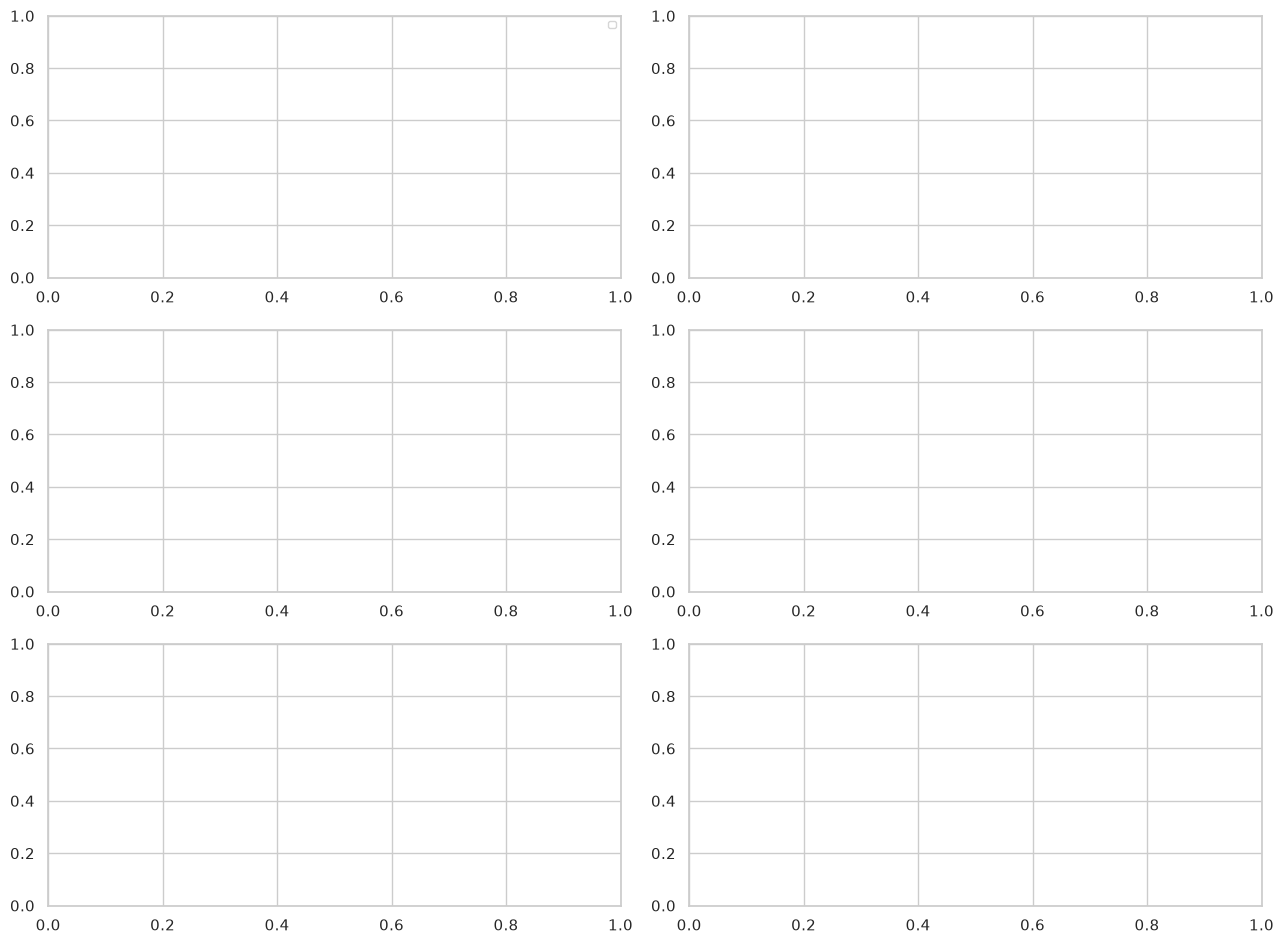

In [27]:
fig, axes = plt.subplots(len(GROUPS), 2, figsize=(13, 3.2 * len(GROUPS)))
 
for row, group_name in enumerate(GROUPS):
    subj_dir = sample_subject_dir(group_name, seed=row)
    files = sorted(subj_dir.glob("*.edf"))
    rest_f = next((f for f in files if classify_file(f.stem) == "rest"), None)
    task_f = next((f for f in files if classify_file(f.stem) == "task_1"), None)
 
    if rest_f:
        plot_raw_snippet(rest_f, axes[row, 0], f"{group_name} / {subj_dir.name} — покой")
    if task_f:
        plot_raw_snippet(task_f, axes[row, 1], f"{group_name} / {subj_dir.name} — таблица №1")
 
axes[0, 0].legend(fontsize=7, loc="upper right")
plt.tight_layout()
plt.show()

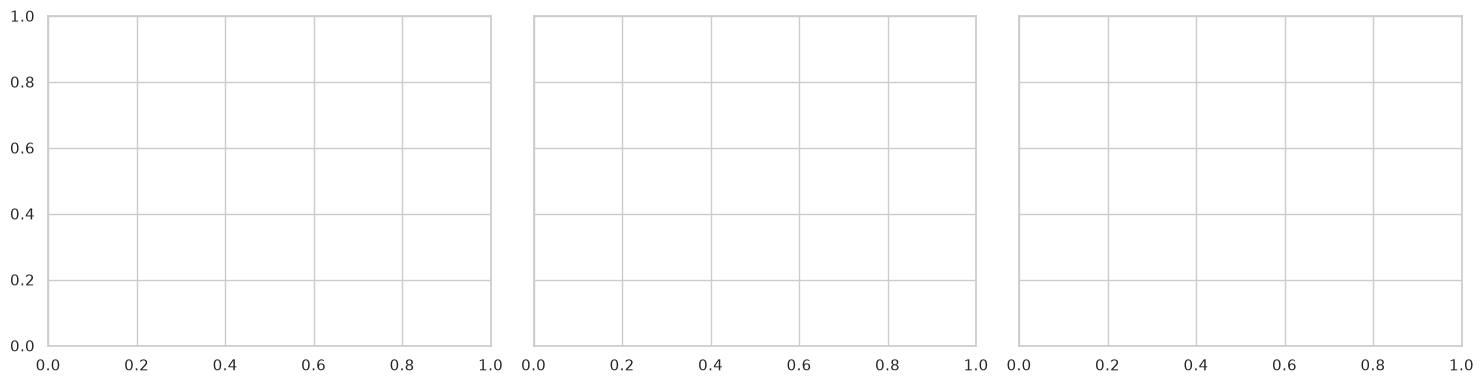

In [28]:
# то же самое, но в частотной области — сырой (нефильтрованный) спектр
fig, axes = plt.subplots(1, len(GROUPS), figsize=(15, 4), sharey=True)
 
for i, group_name in enumerate(GROUPS):
    subj_dir = sample_subject_dir(group_name, seed=i)
    rest_f = next((f for f in subj_dir.glob("*.edf") if classify_file(f.stem) == "rest"), None)
    if rest_f is None:
        continue
    raw = mne.io.read_raw_edf(rest_f, preload=True, verbose=False)
    raw.pick(CHANNELS)
    raw.compute_psd(fmax=60).plot(axes=axes[i], show=False)
    axes[i].set_title(f"{group_name}\\n{subj_dir.name} — покой, сырой спектр")
 
plt.tight_layout()
plt.show()

**На что смотреть здесь:** есть ли уже на сыром спектре пик 50 Гц (сетевая
наводка — должен уйти после notch-фильтра в препроцессинге), насколько
выражен альфа-пик 8-13 Гц в покое (глаза закрыты — должен быть заметен,
особенно на O1/O2), нет ли совсем плоских или "зашкаливающих" каналов уже
на этом этапе.

### Артефакты и выбросы: первичная (грубая) детекция

Без полноценного препроцессинга — просто чтобы понять масштаб проблемы:
сколько файлов имеют подозрительно плоские или подозрительно шумные
каналы. Именно эта диагностика в следующем ноутбуке ляжет в основу
`detect_bad_channels`.

In [30]:
def raw_channel_stats(path):
    raw = mne.io.read_raw_edf(path, preload=True, verbose=False)
    raw.pick(CHANNELS)
    data = raw.get_data() * 1e6
    return {ch: dict(std=float(data[i].std()), ptp=float(np.ptp(data[i])))
            for i, ch in enumerate(CHANNELS)}

In [31]:
random.seed(1)
sample_files = []
for group_dir in sorted(DATA_DIR.iterdir()):
    if not group_dir.is_dir():
        continue
    subj_dirs = [d for d in group_dir.iterdir() if d.is_dir()]
    for subj_dir in random.sample(subj_dirs, min(20, len(subj_dirs))):
        for f in subj_dir.glob("*.edf"):
            sample_files.append((group_dir.name, subj_dir.name, f))
 
chstat_rows = []
for group, subj, f in sample_files:
    try:
        stats_ = raw_channel_stats(f)
        for ch, s in stats_.items():
            chstat_rows.append(dict(group=group, subject=subj, file=f.name,
                                     kind=classify_file(f.stem), channel=ch, **s))
    except Exception as e:
        chstat_rows.append(dict(group=group, subject=subj, file=f.name, error=str(e)))
 
chstat_df = pd.DataFrame(chstat_rows)


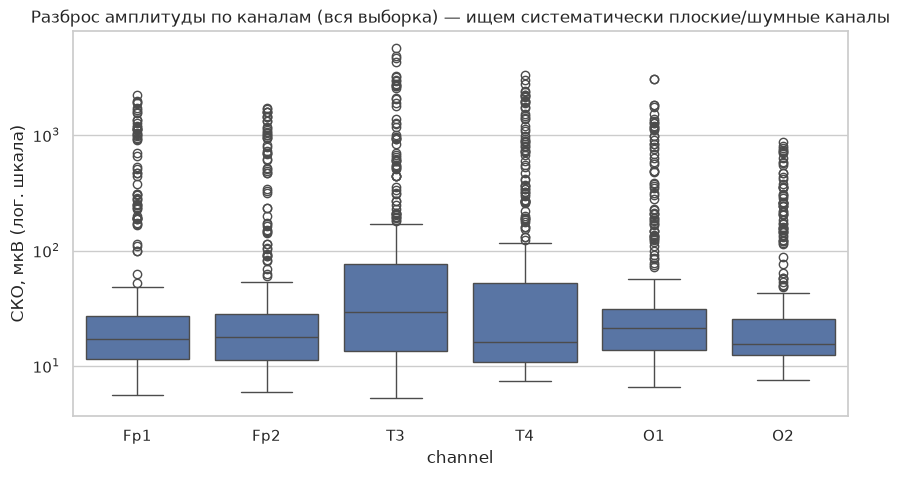

In [32]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=chstat_df, x="channel", y="std", order=CHANNELS)
plt.yscale("log")
plt.ylabel("СКО, мкВ (лог. шкала)")
plt.title("Разброс амплитуды по каналам (вся выборка) — ищем систематически плоские/шумные каналы")
plt.show()

In [34]:
# грубая эвристика для количественной оценки масштаба проблемы (финальные пороги — в след. ноутбуке)
flat_thresh_uv, noisy_ptp_uv = 0.5, 2000
 
flagged = chstat_df[(chstat_df["std"] < flat_thresh_uv) | (chstat_df["ptp"] > noisy_ptp_uv)]
print(f"Файлов×каналов с подозрением на артефакт: {len(flagged)} из {len(chstat_df)}")
print("\nПо каналам:")
print(flagged["channel"].value_counts())
print("\nПо группам:")
print(flagged["group"].value_counts())

Файлов×каналов с подозрением на артефакт: 399 из 2160

По каналам:
channel
T3     84
T4     76
O1     64
O2     59
Fp1    58
Fp2    58
Name: count, dtype: int64

По группам:
group
Соматоформные    264
ПТСР             130
Норма              5
Name: count, dtype: int64


Если один и тот же канал (например, T3 или T4 — они чаще всего страдают у
подобных гарнитур из-за посадки на височную область с волосами) регулярно
всплывает как проблемный — это системная особенность гарнитуры/посадки, а
не случайность, и это стоит явно отметить в отчёте.

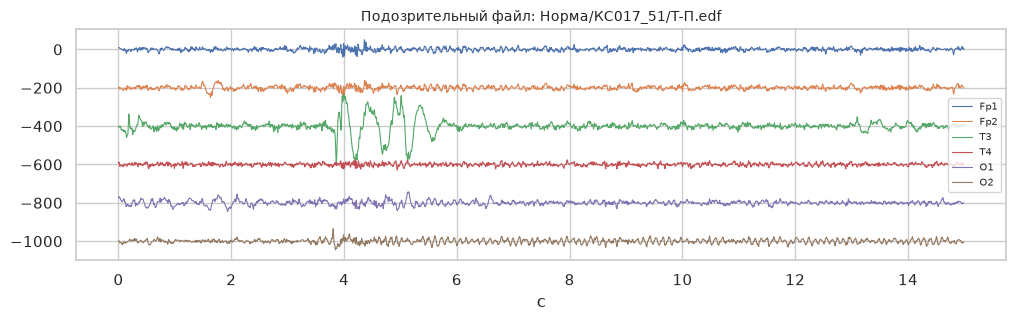

In [35]:
# пример одного явно "грязного" файла — посмотреть глазами, что там происходит
if len(flagged):
    example_bad = flagged.iloc[0]
    bad_path = DATA_DIR / example_bad["group"] / example_bad["subject"] / example_bad["file"]
    fig, ax = plt.subplots(figsize=(12, 3))
    plot_raw_snippet(bad_path, ax, f"Подозрительный файл: {example_bad['group']}/{example_bad['subject']}/{example_bad['file']}",
                      secs=15)
    ax.legend(fontsize=7)
    plt.show()

### Проверка систематической асимметрии из-за референса на левом ухе

**Ключевая проверка перед любыми выводами про межполушарную асимметрию.**
Референсный электрод — на левом ухе, значит левые каналы (Fp1, T3, O1)
физически ближе к референсу, чем правые (Fp2, T4, O2). Если это создаёт
систематическое смещение амплитуды, оно будет видно **на всей выборке
целиком, независимо от группы** — то есть это проверка не про ПТСР, а про
саму схему отведения.

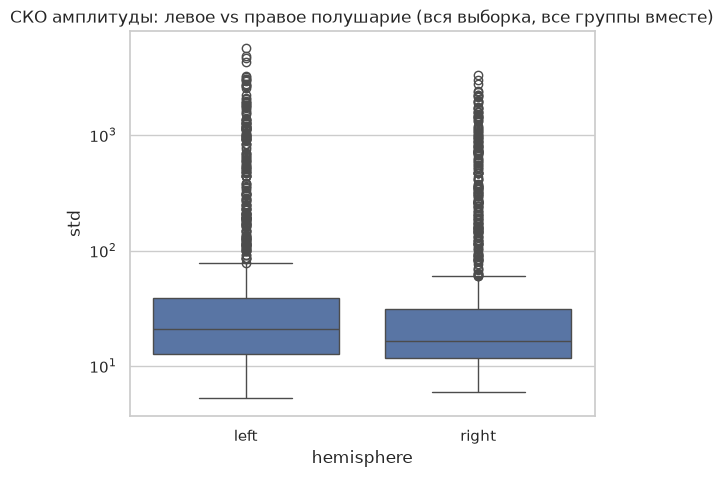

Mann-Whitney U, левые vs правые каналы (вся выборка): p=0.0000
Медиана СКО: левые=20.8 мкВ, правые=16.4 мкВ


In [36]:
hemis = chstat_df[chstat_df["channel"].isin(LEFT_CH + RIGHT_CH)].copy()
hemis["hemisphere"] = hemis["channel"].map(lambda c: "left" if c in LEFT_CH else "right")
 
plt.figure(figsize=(6, 5))
sns.boxplot(data=hemis, x="hemisphere", y="std")
plt.yscale("log")
plt.title("СКО амплитуды: левое vs правое полушарие (вся выборка, все группы вместе)")
plt.show()
 
left_std = hemis.loc[hemis["hemisphere"] == "left", "std"]
right_std = hemis.loc[hemis["hemisphere"] == "right", "std"]
w_stat, p_val = sps.mannwhitneyu(left_std, right_std)
print(f"Mann-Whitney U, левые vs правые каналы (вся выборка): p={p_val:.4f}")
print(f"Медиана СКО: левые={left_std.median():.1f} мкВ, правые={right_std.median():.1f} мкВ")

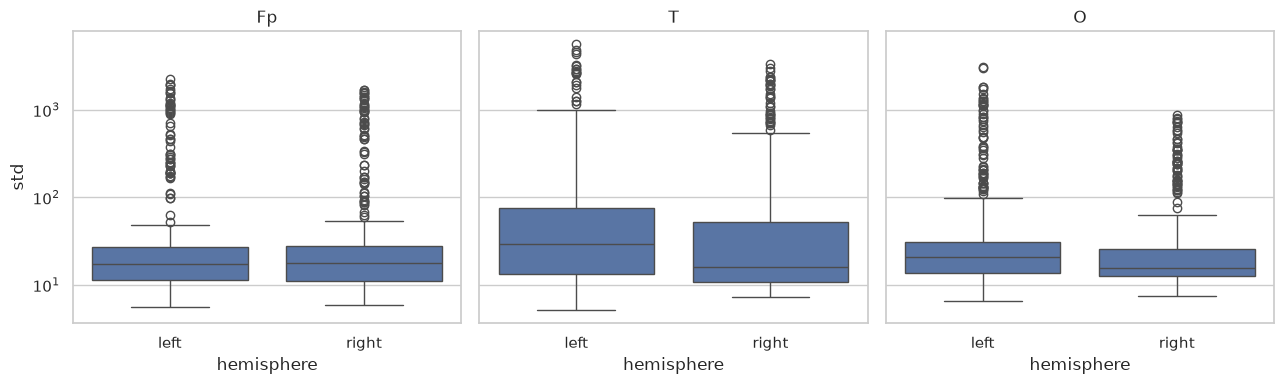

In [37]:
# то же самое попарно, по каждой из трёх осей Fp/T/O — вдруг эффект референса
# сильнее выражен на ближних к уху каналах (T), чем на дальних (Fp, O)
pair_names = {"Fp1": "Fp", "Fp2": "Fp", "T3": "T", "T4": "T", "O1": "O", "O2": "O"}
hemis["pair"] = hemis["channel"].map(pair_names)
 
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for i, pair in enumerate(["Fp", "T", "O"]):
    sub = hemis[hemis["pair"] == pair]
    sns.boxplot(data=sub, x="hemisphere", y="std", ax=axes[i])
    axes[i].set_yscale("log")
    axes[i].set_title(pair)
plt.tight_layout()
plt.show()

**Как трактовать:**
- Если левые/правые каналы систематически различаются по амплитуде **на
  всей выборке** (не только внутри одной группы) — это инструментальный
  эффект референса, а не физиология. В таком случае в следующем ноутбуке
  обязателен шаг **re-reference на средний по 6 каналам** перед вычислением
  любых асимметрия-признаков и признаков связности — иначе `asym_*`
  признаки будут частично или полностью кодировать не ПТСР, а
  геометрию электродов.
- Если эффект сильнее всего на T (ближайшая к уху пара) и слабее на Fp/O —
  это дополнительное подтверждение, что дело именно в удалённости от
  референса, а не в реальной височной асимметрии.
- Эта проверка **не отменяет** возможность реальной физиологической
  асимметрии при ПТСР — она отделяет инструментальный эффект от него,
  чтобы re-reference в следующем ноутбуке не был "слепой" мерой предосторожности,
  а был обоснован тем, что видно здесь.

### Распределения по группам: грубые спектральные признаки

Без ICA/фильтрации артефактов — просто относительная мощность по
диапазонам на сыром сигнале (после базового bandpass 1-40 Гц, только чтобы
убрать дрейф и совсем высокочастотный шум), чтобы увидеть, есть ли вообще
визуально различимый сигнал между группами до какой-либо тонкой очистки.
Финальные признаки для модели считаются в следующем ноутбуке на полностью
очищенных данных — здесь только ориентировочная картина.

In [38]:
BANDS = {"delta": (1, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (13, 30), "gamma": (30, 40)}
 
 
def quick_rel_power(path):
    raw = mne.io.read_raw_edf(path, preload=True, verbose=False)
    raw.pick(CHANNELS)
    raw.filter(1, 40, method="iir", verbose=False)
    data = raw.get_data() * 1e6
    fs = raw.info["sfreq"]
    f, p = signal.welch(data, fs=fs, nperseg=min(int(4 * fs), data.shape[1]), axis=-1)
    total = p[:, (f >= 1) & (f <= 40)].sum(axis=1, keepdims=True)
    return {band: (p[:, (f >= lo) & (f < hi)].sum(axis=1) / total[:, 0])
            for band, (lo, hi) in BANDS.items()}, f, p


In [39]:
random.seed(2)
eda_feat_rows = []
for group_dir in sorted(DATA_DIR.iterdir()):
    if not group_dir.is_dir():
        continue
    subj_dirs = [d for d in group_dir.iterdir() if d.is_dir()]
    for subj_dir in random.sample(subj_dirs, min(25, len(subj_dirs))):
        rest_f = next((f for f in subj_dir.glob("*.edf") if classify_file(f.stem) == "rest"), None)
        if rest_f is None:
            continue
        try:
            rp, _, _ = quick_rel_power(rest_f)
            row = dict(group=group_dir.name, subject=subj_dir.name,
                       age=get_age(group_dir.name, subj_dir.name))
            for band, vals in rp.items():
                for i, ch in enumerate(CHANNELS):
                    row[f"{ch}_{band}"] = float(vals[i])
            eda_feat_rows.append(row)
        except Exception:
            pass
 
eda_feat_df = pd.DataFrame(eda_feat_rows)
print(eda_feat_df.shape)


(0, 0)


KeyError: "The following id_vars or value_vars are not present in the DataFrame: ['group', 'O1_delta', 'O2_delta']"

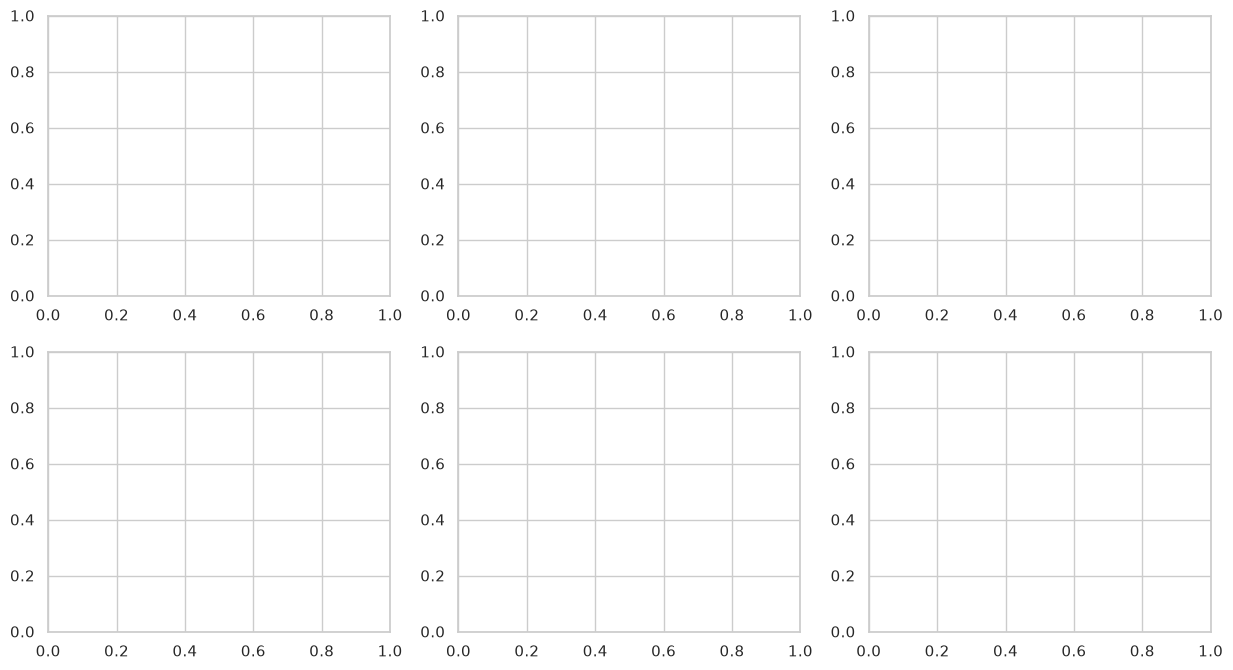

In [40]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, band in zip(axes.flat, BANDS):
    cols = [f"{ch}_{band}" for ch in ["O1", "O2"]]   # затылочные — самый чувствительный к состоянию покоя регион
    plot_df = eda_feat_df.melt(id_vars="group", value_vars=cols, var_name="channel", value_name="rel_power")
    sns.boxplot(data=plot_df, x="group", y="rel_power", hue="channel", order=GROUPS, ax=ax)
    ax.set_title(f"O1/O2, {band}")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

In [41]:
# то же в виде таблицы: медианы по группам, чтобы явно видеть направление разницы
summary_by_group = eda_feat_df.groupby("group")[[c for c in eda_feat_df.columns
                                                    if c not in ("group", "subject", "age")]].median()
summary_by_group.T.loc[[c for c in summary_by_group.columns if False] or
                         [f"{ch}_alpha" for ch in CHANNELS]]

KeyError: 'group'

In [42]:
# t-SNE как чисто разведочная визуализация структуры (НЕ как доказательство разделимости — на LOO это не проверка)
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
 
feat_cols_quick = [c for c in eda_feat_df.columns if c not in ("group", "subject", "age")]
X_quick = SimpleImputer(strategy="median").fit_transform(eda_feat_df[feat_cols_quick])
X_quick = StandardScaler().fit_transform(X_quick)
 
emb = TSNE(n_components=2, perplexity=15, random_state=RANDOM_STATE, init="pca").fit_transform(X_quick)
 
plt.figure(figsize=(7, 6))
sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=eda_feat_df["group"], hue_order=GROUPS, s=60)
plt.title("t-SNE по грубым спектральным признакам покоя (только для интуиции, не для выводов)")
plt.show()

ValueError: at least one array or dtype is required

**Важная оговорка про t-SNE:** это чисто разведочный инструмент — он не
валидируется через LOSO и легко "рисует" кажущиеся кластеры даже на шуме
при малой выборке. Использовать только для генерации гипотез, не для
утверждений о разделимости групп — те уже проверяются моделью в
следующем ноутбуке.

### Первичные гипотезы о признаках, связанных с ПТСР

По итогам разделов 4–7 (заполнить после реального просмотра графиков —
ниже шаблон с ожидаемыми по литературе направлениями, которые нужно
подтвердить/опровергнуть на своих данных):
 
1. **Подавление альфа-ритма в покое на O1/O2** (глаза закрыты) —
   гипервозбуждение коры при ПТСР; проверяется в раздел 7 boxplot'ах выше.
2. **Более плоский наклон 1/f (апериодический компонент)** на фронтальных
   каналах — повышенное отношение возбуждение/торможение; в этом ноутбуке
   не считается (нужна аккуратная подгонка — в следующем ноутбуке), но
   первичный сигнал может быть виден уже на "приподнятой" высокочастотной
   части спектра на графиках раздела 4.
3. **Повышенная бета-мощность** на фронтальных отведениях — гипербдительность.
4. **Межполушарная асимметрия Fp1/Fp2** — с обязательной поправкой на
   инструментальный эффект референса (раздел 6).
5. **Поведенческие показатели** (время решения таблиц) — медленнее и/или
   более вариабельно при ПТСР; см. раздел 9.
 
Каждая гипотеза тестируется количественно (не на глаз) в следующем
ноутбуке, с LOSO-валидацией и контролем конфаундеров.

### Доступные конфаундеры: возраст, пол, поведенческие показатели

Явно фиксируем, что из потенциальных конфаундеров у нас вообще есть, а
что — нет (и почему).

Возраст известен только для группы 'Норма' (п. 3.1 ТЗ):
group
Норма            0
ПТСР             0
Соматоформные    0
Name: age, dtype: int64


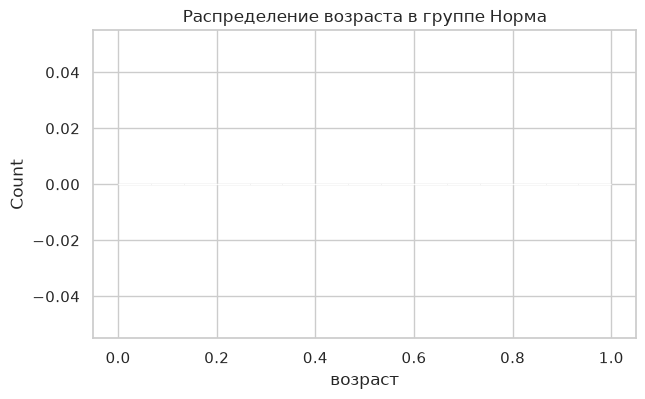

In [44]:
print("Возраст известен только для группы 'Норма' (п. 3.1 ТЗ):")
print(inv_df.groupby("group")["age"].apply(lambda s: s.notna().sum()))
 
plt.figure(figsize=(7, 4))
sns.histplot(inv_df.loc[inv_df["group"].str.lower().str.startswith("норм"), "age"], bins=15)
plt.title("Распределение возраста в группе Норма")
plt.xlabel("возраст")
plt.show()

**Пол.** В структуре данных (имена файлов/папок) пол испытуемого никак не
закодирован, доступна только сводка по группам в целом (п. 3.1 ТЗ:
контроль и ПТСР — мужчины, соматоформная группа смешанная по полу). Это
значит:
- пол **нельзя** использовать как признак или проверить как конфаундер
  на уровне отдельного испытуемого — только на уровне описания выборки
  в отчёте (группа ПТСР состоит из мужчин, это ограничение
  генерализуемости, а не то, что можно скорректировать в модели);
- при сравнении ПТСР vs Норма пол в целом сбалансирован по построению
  выборки (обе группы — мужчины), а вот соматоформная группа (проверка
  специфичности) смешанная — при интерпретации результатов на ней это
  стоит держать в уме.

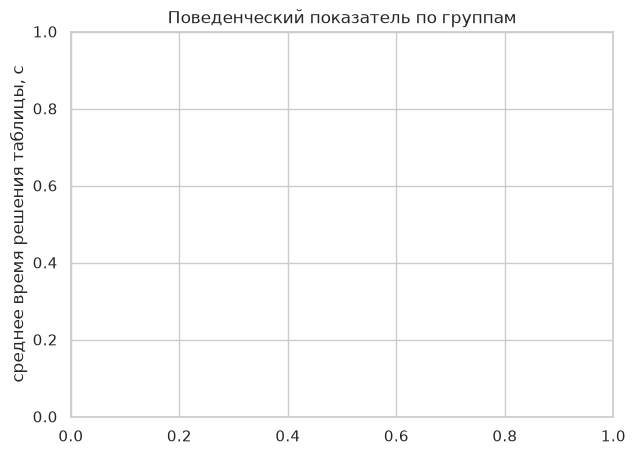

Empty DataFrame
Columns: [count, mean, std, min, 25%, 50%, 75%, max]
Index: []


In [45]:
# поведенческие показатели — длительность решения таблиц, по группам
task_meta = meta_df[meta_df["kind"].str.startswith("task")].copy()
subj_mean_dur = task_meta.groupby(["group", "subject"])["duration_s"].mean().reset_index()
 
plt.figure(figsize=(7, 5))
sns.boxplot(data=subj_mean_dur, x="group", y="duration_s", order=GROUPS)
sns.stripplot(data=subj_mean_dur, x="group", y="duration_s", order=GROUPS, color="black", alpha=0.4, size=3)
plt.ylabel("среднее время решения таблицы, с")
plt.title("Поведенческий показатель по группам")
plt.show()
 
print(subj_mean_dur.groupby("group")["duration_s"].describe())


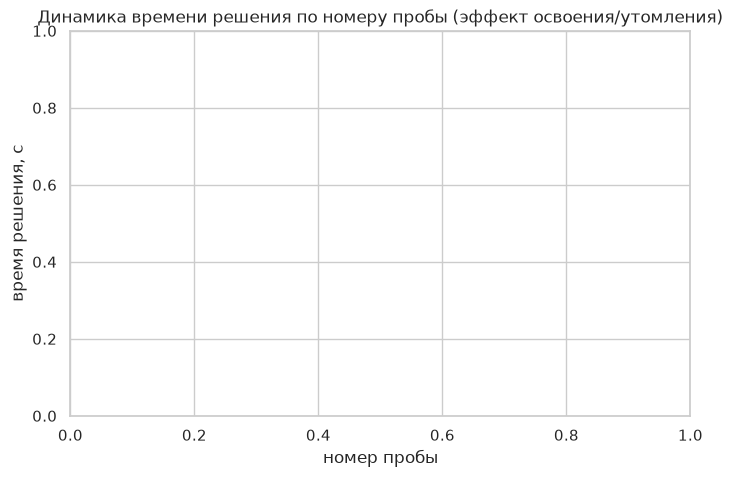

In [46]:
# первая проба обычно медленнее остальных (эффект освоения задачи, см. Приложение 1) —
# проверяем, что это не различается по группам патологически (иначе first-try эффект = конфаундер)
task_meta["task_n"] = task_meta["kind"].str.extract(r"task_(\\d+)").astype(int)
 
plt.figure(figsize=(8, 5))
sns.lineplot(data=task_meta, x="task_n", y="duration_s", hue="group", hue_order=GROUPS,
             estimator="median", errorbar=("ci", 95), marker="o")
plt.xlabel("номер пробы")
plt.ylabel("время решения, с")
plt.title("Динамика времени решения по номеру пробы (эффект освоения/утомления)")
plt.show()

In [47]:
# возраст vs время решения внутри Нормы — если коррелирует, поведенческий признак
# частично конфаундирован возрастом, это нужно знать до моделирования
norm_beh = subj_mean_dur[subj_mean_dur["group"].str.lower().str.startswith("норм")].merge(
    inv_df[["group", "subject", "age"]], on=["group", "subject"]
)
r_age_beh, p_age_beh = sps.pearsonr(norm_beh["age"].dropna(),
                                     norm_beh.loc[norm_beh["age"].notna(), "duration_s"])
print(f"Возраст vs время решения (Норма): r={r_age_beh:.3f}, p={p_age_beh:.3f}")
 
plt.figure(figsize=(6, 5))
sns.regplot(data=norm_beh, x="age", y="duration_s")
plt.title("Возраст vs время решения таблиц (Норма)")
plt.show()

ValueError: `x` and `y` must have length at least 2.

### Резюме разведовочного анализа

Коротко зафиксировать перед переходом к препроцессингу и моделированию
(заполнить по факту прогона):
- список испытуемых-кандидатов на исключение (`EXCLUDE_SUBJECTS` в
  следующем ноутбуке) — из разделов 2 и 5;
- подтверждён/не подтверждён инструментальный эффект референса на левом
  ухе (раздел 6) → нужен ли обязательный шаг re-reference;
- какие частоты дискретизации встречаются и надо ли их учитывать отдельно
  (раздел 3);
- список гипотез из раздела 8 — какие проверять в первую очередь.